# CSE558 Data Science: Assignment, Question 2
## JL for linear regression (sketch-and-solve with CountSketch)

This notebook does every part of Question 2, step by step.

| Step | What it does |
|---|---|
| 0 | Set the seeds, load KDD Cup 99 (10%), build the data matrix $D$ and the label vector $y$ |
| (a) | Solve the full least-squares problem: $b = \arg\min_a \|Da-y\|_2^2$ |
| (b) | CountSketch $S\in\mathbb{R}^{m\times n}$, solve $\tilde a=\arg\min_a\|SDa-Sy\|_2^2$, compare $\text{Loss}(D,y,\tilde a)$ with $\text{Loss}(D,y,b)$ |
| (c) | Time the sketch-and-solve pipeline and compare it with the full solve |
| (d) | Check the JL property of CountSketch on one fixed vector: $\|Sv\|_2^2/\|v\|_2^2$ for the residual $v=Db-y$ |
| (e) | On a 50,000-row subset, compare CountSketch with a dense Gaussian sketch |

**Reproducibility.** Every random number comes from the master seed `SEED = 558`. Each part gets its own generator
(made with `numpy.random.SeedSequence(SEED).spawn`), so rerunning one part does not change the numbers of another.
Losses and ratios are exactly reproducible. Wall-clock times change a little from run to run and from machine to machine.

**Rules from the question.** All least-squares problems use `numpy.linalg.lstsq`. The CountSketch matrix $S$ is never stored:
we store only the bucket $h(i)$ and the sign $\sigma(i)$ of each row, and add the rows with `numpy.add.at`.
No `sklearn.random_projection` is used.

In [1]:
import json, platform, subprocess, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99

SEED = 558
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)

# one independent random generator per part, all derived from SEED
ss = np.random.SeedSequence(SEED).spawn(6)
rng_b, rng_d, rng_e_subset, rng_e_count, rng_e_gauss, rng_full = (np.random.default_rng(s) for s in ss)

# plot style: neutral ink, light grid, fixed series colours
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"        # blue, orange, aqua
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
})
pd.set_option("display.width", 160)

try:    # CPU name on macOS; elsewhere fall back to platform.processor()
    CPU = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()
except OSError:
    CPU = ""
CPU = CPU or platform.processor()
print("numpy", np.__version__, "| pandas", pd.__version__, "|", platform.platform(), "|", CPU)

numpy 1.26.4 | pandas 2.3.2 | macOS-15.7.3-arm64-arm-64bit | Apple M4


### Helper functions

* `loss(D, y, a)` returns $\text{Loss}(D,y,a)=\|Da-y\|_2^2$.
* `draw_countsketch(rng, m, n)` draws a CountSketch $S\in\mathbb{R}^{m\times n}$. It stores only two arrays of length $n$:
  the bucket $h(i)\in\{0,\dots,m-1\}$ and the sign $\sigma(i)\in\{-1,+1\}$, each drawn uniformly and independently.
  Column $i$ of $S$ has a single nonzero entry, $S_{h(i),i}=\sigma(i)$.
* `apply_countsketch(h, sigma, m, X)` returns $SX$ in one pass over the rows of $X$: row $i$ of $X$, times $\sigma(i)$,
  is added to row $h(i)$ of $SX$ (`numpy.add.at`). It works for a matrix ($SD$) and for a vector ($Sy$, $Sv$).

In [2]:
def loss(D, y, a):
    # Loss(D, y, a) = ||D a - y||_2^2
    r = D @ a - y
    return float(r @ r)

def lstsq(M, z):
    return np.linalg.lstsq(M, z, rcond=None)[0]

def draw_countsketch(rng, m, n):
    # S is kept as two length-n arrays, never as an m x n matrix
    h = rng.integers(0, m, size=n)                     # bucket h(i), uniform on {0, ..., m-1}
    sigma = rng.choice(np.array([-1.0, 1.0]), size=n)  # sign sigma(i), uniform on {-1, +1}
    return h, sigma

def apply_countsketch(h, sigma, m, X):
    # S X: add sigma(i) * X[i] to row h(i), one pass over the rows of X
    SX = np.zeros((m,) + X.shape[1:])
    signed = sigma[:, None] * X if X.ndim == 2 else sigma * X
    np.add.at(SX, h, signed)
    return SX

# sanity check against an explicit dense S on a tiny example
_rng = np.random.default_rng(0)
_X, _m = _rng.standard_normal((7, 3)), 4
_h, _s = draw_countsketch(_rng, _m, 7)
_S = np.zeros((_m, 7)); _S[_h, np.arange(7)] = _s
assert np.allclose(apply_countsketch(_h, _s, _m, _X), _S @ _X)
print("apply_countsketch matches the dense product S @ X on a small example")

apply_countsketch matches the dense product S @ X on a small example


## Step 0: Build $D$ and $y$

Following the "Data" instructions:

1. **One-hot encode** the three text features `protocol_type`, `service` and `flag`, and convert the other 38 features to float.
2. **Drop every constant column** (a column that takes the same value on all rows).
3. **Rescale each column to $[0,1]$** with $x\mapsto (x-\min)/(\max-\min)$.

The label is $y_i = 1$ if connection $i$ is an attack (its label is not `b'normal.'`) and $y_i=0$ otherwise.
We keep $D$ in float64: it needs about 460 MB, which fits in memory, and float64 keeps `lstsq` accurate.

In [3]:
kdd = fetch_kddcup99(subset=None, as_frame=True)
X = kdd.data.copy()
text_cols = ["protocol_type", "service", "flag"]
for c in text_cols:
    X[c] = X[c].str.decode("utf-8")              # b'tcp' -> 'tcp', so the column names read well
num_cols = [c for c in X.columns if c not in text_cols]

# (i) one-hot encode the 3 text features, other 38 features to float
F = pd.concat([X[num_cols].astype(float), pd.get_dummies(X[text_cols], dtype=float)], axis=1)
n_onehot = F.shape[1]

# (ii) drop every column that is constant on all rows
constant_cols = F.columns[F.nunique() == 1].tolist()
F = F.drop(columns=constant_cols)

# (iii) rescale each column to [0, 1]
F = (F - F.min()) / (F.max() - F.min())

D = F.to_numpy(dtype=np.float64)
y = (kdd.target != b"normal.").to_numpy(dtype=float)
n, d = D.shape
rank_D = int(np.linalg.matrix_rank(D))

print(f"categories: protocol_type {X.protocol_type.nunique()}, service {X.service.nunique()}, flag {X.flag.nunique()}")
print(f"columns after one-hot encoding: {n_onehot} (= 38 numeric + 80 one-hot)")
print(f"constant columns dropped: {constant_cols}")
print(f"D has n = {n} rows and d = {d} columns;  rank(D) = {rank_D}")
print(f"y: {int(y.sum())} attacks (y=1) and {int(n - y.sum())} normal (y=0); fraction of attacks = {y.mean():.4f}")
print(f"min and max of D: {D.min()}, {D.max()}")

categories: protocol_type 3, service 66, flag 11
columns after one-hot encoding: 118 (= 38 numeric + 80 one-hot)
constant columns dropped: ['num_outbound_cmds', 'is_host_login']
D has n = 494021 rows and d = 116 columns;  rank(D) = 113
y: 396743 attacks (y=1) and 97278 normal (y=0); fraction of attacks = 0.8031
min and max of D: 0.0, 1.0


### Why is $\text{rank}(D) = 113 < d = 116$?

Three exact linear relations hold among the columns of $D$ (the one-hot columns stay 0/1 after rescaling):

1. the `protocol_type_*` columns add up to the all-ones vector;
2. the `service_*` columns add up to the all-ones vector, so (1) minus (2) is a relation;
3. the `flag_*` columns add up to the all-ones vector, so (1) minus (3) is a relation;
4. the six ICMP services (`eco_i, ecr_i, red_i, tim_i, urh_i, urp_i`) occur only with protocol ICMP, and ICMP rows use only them,
   so `protocol_type_icmp` equals the sum of those six service columns.

These give 3 independent relations, so the rank is $116-3=113$. The cell below checks all of them.
This number matters in part (b): a sketch with fewer than 113 rows cannot keep the column space of $D$.

In [4]:
cols = list(F.columns)
group = lambda p: [c for c in cols if c.startswith(p)]
icmp_services = sorted(X.loc[X.protocol_type == "icmp", "service"].unique())
print("ICMP services:", icmp_services)
print("they occur only with ICMP:", all(set(X.loc[X.service == s, "protocol_type"]) == {"icmp"} for s in icmp_services))
print("protocol_type columns sum to 1:", np.allclose(F[group("protocol_type_")].sum(axis=1), 1))
print("service columns sum to 1:      ", np.allclose(F[group("service_")].sum(axis=1), 1))
print("flag columns sum to 1:         ", np.allclose(F[group("flag_")].sum(axis=1), 1))
print("protocol_type_icmp = sum of ICMP service columns:",
      np.allclose(F["protocol_type_icmp"], F[["service_" + s for s in icmp_services]].sum(axis=1)))
sv = np.linalg.svd(D, compute_uv=False)
print("smallest 5 singular values of D:", np.array2string(sv[-5:], precision=3))

ICMP services: ['eco_i', 'ecr_i', 'red_i', 'tim_i', 'urh_i', 'urp_i']


they occur only with ICMP: True
protocol_type columns sum to 1: True


service columns sum to 1:       True
flag columns sum to 1:          True
protocol_type_icmp = sum of ICMP service columns: True


smallest 5 singular values of D:

 [9.907e-01 1.061e-01 1.979e-10 1.508e-10 1.087e-10]


## Part (a): The full least-squares solution $b$

We solve $b=\arg\min_a\|Da-y\|_2^2$ with `numpy.linalg.lstsq` on all $n$ rows.
Because $D$ has rank $113<116$, the minimiser is not unique; `lstsq` returns the one with the smallest norm. The minimum loss is unique.
To get a stable time we solve the problem 5 times and report the mean.

In [5]:
times_a = []
for _ in range(5):
    t0 = time.perf_counter()
    b = lstsq(D, y)
    times_a.append(time.perf_counter() - t0)
time_a = float(np.mean(times_a))
loss_b = loss(D, y, b)

print(f"Loss(D, y, b) = {loss_b:.4f}   (||b||_2 = {np.linalg.norm(b):.4f})")
print(f"mean squared residual Loss/n = {loss_b / n:.6f}  (RMS residual {np.sqrt(loss_b / n):.4f})")
print(f"for comparison ||y||^2 = {y @ y:.0f} and ||y - mean(y)||^2 = {np.sum((y - y.mean())**2):.1f}")
print("time to compute b (5 runs):", np.round(times_a, 3), f"-> mean {time_a:.3f} s")

Loss(D, y, b) = 2949.7888   (||b||_2 = 135.2916)
mean squared residual Loss/n = 0.005971  (RMS residual 0.0773)
for comparison ||y||^2 = 396743 and ||y - mean(y)||^2 = 78122.9
time to compute b (5 runs): [1.713 1.528 1.531 1.669 1.587] -> mean 1.606 s


## Part (b): Sketch-and-solve with CountSketch

For each $m\in\{50,100,200,500,1000,2000,5000\}$ and each of 5 repetitions (a fresh $S$ every time):

1. draw $S$ (that is, draw $h$ and $\sigma$);
2. form $SD\in\mathbb{R}^{m\times d}$ and $Sy\in\mathbb{R}^m$ in one pass with `apply_countsketch`;
3. solve $\tilde a=\arg\min_a\|SDa-Sy\|_2^2$ with `lstsq`;
4. record $\text{Loss}(D,y,\tilde a)$, the ratio $\text{Loss}(D,y,\tilde a)/\text{Loss}(D,y,b)$, the sketched loss $\|SD\tilde a-Sy\|_2^2$
   $\text{rank}(SD)$, the smallest nonzero singular value of $SD$ and $\|\tilde a\|_2$ (these two explain the shape of the curve).

Steps 1 to 3 are timed (they are used again in part (c)). Step 4 is not timed.

In [6]:
M_LIST = [50, 100, 200, 500, 1000, 2000, 5000]
REPS = 5
rows = []
for m in M_LIST:
    for rep in range(1, REPS + 1):
        t0 = time.perf_counter()
        h, sigma = draw_countsketch(rng_b, m, n)        # 1. draw S
        t1 = time.perf_counter()
        SD = apply_countsketch(h, sigma, m, D)          # 2. form SD and Sy
        Sy = apply_countsketch(h, sigma, m, y)
        t2 = time.perf_counter()
        a_t = lstsq(SD, Sy)                             # 3. solve the sketched problem
        t3 = time.perf_counter()
        L = loss(D, y, a_t)                             # 4. record
        sv_SD = np.linalg.svd(SD, compute_uv=False)
        rk = int(np.sum(sv_SD > sv_SD[0] * max(SD.shape) * np.finfo(float).eps))   # same rule as matrix_rank
        rows.append(dict(m=m, rep=rep, loss=L, ratio=L / loss_b, sketched_loss=loss(SD, Sy, a_t),
                         rank_SD=rk, smin_SD=sv_SD[rk - 1], norm_a=float(np.linalg.norm(a_t)),
                         t_draw=t1 - t0, t_form=t2 - t1, t_solve=t3 - t2, t_total=t3 - t0))
runs_b = pd.DataFrame(rows)
runs_b.to_csv(RES / "q2b_all_runs.csv", index=False)

with pd.option_context("display.float_format", "{:.6g}".format):
    print(runs_b[["m", "rep", "loss", "ratio", "sketched_loss", "rank_SD", "smin_SD", "norm_a"]].to_string(index=False))
print(f"for comparison: ||b|| = {np.linalg.norm(b):.4g}, smallest nonzero singular value of D = {sv[rank_D - 1]:.4g}")

   m  rep    loss   ratio  sketched_loss  rank_SD   smin_SD  norm_a
  50    1 11498.8 3.89818    5.75082e-24       50   5.45232 4.94286
  50    2 7264.36 2.46267    9.31156e-25       50   5.68791 4.37212
  50    3   11411 3.86841    4.77476e-24       50   5.38536 5.15663
  50    4 12073.9 4.09316    1.02794e-23       50   4.89698 4.17494
  50    5 12097.9 4.10127    3.32929e-24       50   5.60048 4.83009
 100    1 32883.3 11.1477    1.72355e-23      100  0.401497 21.8648
 100    2 20199.8 6.84788    3.18635e-24      100  0.324739 16.8544
 100    3 66338.9 22.4894    1.28952e-22      100  0.435404 33.2446
 100    4 65310.5 22.1407    4.99817e-23      100  0.468376 30.2706
 100    5 26236.8 8.89447    2.20779e-23      100  0.279664 19.8592
 200    1 6047.56 2.05017        1134.17      113 0.0683738 273.082
 200    2 7982.18 2.70602        1210.64      113 0.0750801 100.043
 200    3 6928.03 2.34865         1471.3      113 0.0701715 144.155
 200    4 7613.69  2.5811        1101.11      11

In [7]:
g = runs_b.groupby("m")
summary_b = pd.DataFrame({
    "ratio_mean": g.ratio.mean(), "ratio_min": g.ratio.min(), "ratio_max": g.ratio.max(),
    "loss_mean": g.loss.mean(),
    "sketched_loss_mean": g.sketched_loss.mean(), "sketched_loss_min": g.sketched_loss.min(),
    "sketched_loss_max": g.sketched_loss.max(),
    "rank_SD": g.rank_SD.min(), "smin_SD_mean": g.smin_SD.mean(), "norm_a_mean": g.norm_a.mean(),
})
summary_b["sketched_over_loss_b"] = summary_b.sketched_loss_mean / loss_b
# reference values: the exact means for a dense Gaussian sketch (derived in the report), defined for m > r + 1
r = rank_D
ms = summary_b.index.to_numpy()
summary_b["ref_ratio_gauss"] = np.where(ms > r + 1, 1 + r / np.maximum(ms - r - 1, 1), np.nan)
summary_b["ref_sketched_over_loss_b_gauss"] = np.where(ms > r, (ms - r) / ms, 0.0)
summary_b.to_csv(RES / "q2b_summary.csv")

with pd.option_context("display.float_format", "{:.6g}".format):
    print(summary_b.to_string())

      ratio_mean  ratio_min  ratio_max  loss_mean  sketched_loss_mean  sketched_loss_min  sketched_loss_max  rank_SD  smin_SD_mean  norm_a_mean  sketched_over_loss_b  ref_ratio_gauss  ref_sketched_over_loss_b_gauss
m                                                                                                                                                                                                                     
50       3.68474    2.46267    4.10127    10869.2         5.01308e-24        9.31156e-25        1.02794e-23       50       5.40461      4.69533           1.69947e-27              NaN                               0
100       14.304    6.84788    22.4894    42193.9         4.42867e-23        3.18635e-24        1.28952e-22      100      0.381936      24.4187           1.50135e-26              NaN                               0
200      2.38378    2.05017    2.70602    7031.64             1264.27            1101.11             1471.3      113     0.0701822      177.

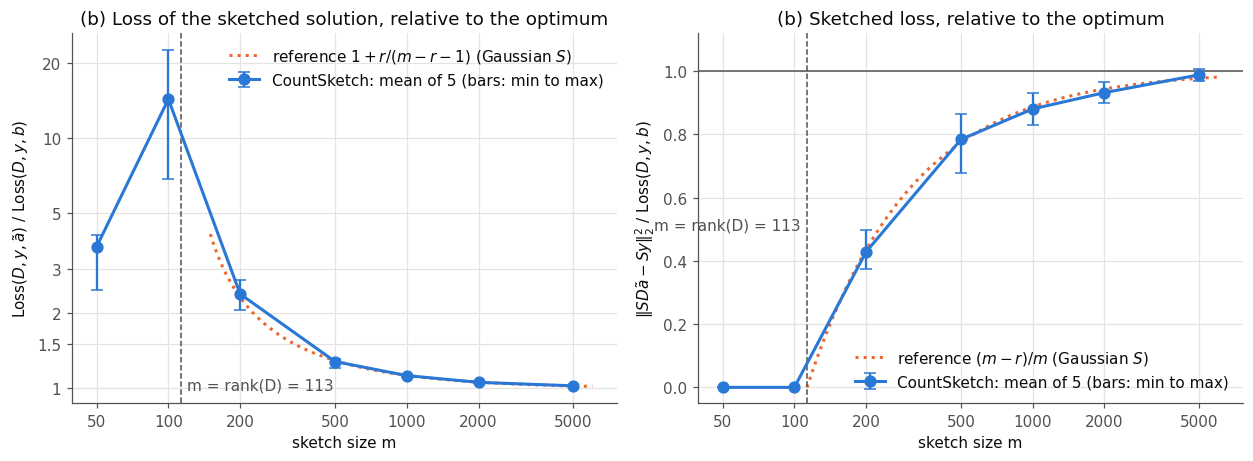

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))
mean, lo, hi = summary_b.ratio_mean, summary_b.ratio_min, summary_b.ratio_max

# left: the ratio Loss(D,y,a~)/Loss(D,y,b) on log-log axes
ax1.errorbar(ms, mean, yerr=[mean - lo, hi - mean], fmt="o-", color=C1, ecolor=C1, elinewidth=1.5,
             capsize=4, label="CountSketch: mean of 5 (bars: min to max)")
mm = np.geomspace(150, 6000, 300)
ax1.plot(mm, 1 + r / (mm - r - 1), ":", color=C2, label=r"reference $1 + r/(m-r-1)$ (Gaussian $S$)")
ax1.axvline(r, color=INK2, ls="--", lw=1)
ax1.text(r * 1.06, 0.03, f"m = rank(D) = {r}", transform=ax1.get_xaxis_transform(), va="bottom", color=INK2)
ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xticks(M_LIST); ax1.set_xticklabels([str(m) for m in M_LIST])
yt = [1, 1.5, 2, 3, 5, 10, 20]
yt = [t for t in yt if lo.min() / 1.1 <= t <= hi.max() * 1.1]
ax1.set_yticks(yt); ax1.set_yticklabels([f"{t:g}" for t in yt]); ax1.minorticks_off()
ax1.set_xlabel("sketch size m"); ax1.set_ylabel(r"Loss$(D,y,\tilde a)$ / Loss$(D,y,b)$")
ax1.set_title("(b) Loss of the sketched solution, relative to the optimum")
ax1.legend(loc="upper right")

# right: the sketched loss ||SDa~ - Sy||^2, divided by Loss(D,y,b)
s_mean = summary_b.sketched_loss_mean / loss_b
s_lo, s_hi = summary_b.sketched_loss_min / loss_b, summary_b.sketched_loss_max / loss_b
ax2.errorbar(ms, s_mean, yerr=[s_mean - s_lo, s_hi - s_mean], fmt="o-", color=C1, ecolor=C1, elinewidth=1.5,
             capsize=4, label="CountSketch: mean of 5 (bars: min to max)")
mm2 = np.geomspace(r, 6000, 300)
ax2.plot(mm2, (mm2 - r) / mm2, ":", color=C2, label=r"reference $(m-r)/m$ (Gaussian $S$)")
ax2.axhline(1, color=INK2, lw=1)
ax2.axvline(r, color=INK2, ls="--", lw=1)
ax2.text(r / 1.06, 0.5, f"m = rank(D) = {r}", color=INK2, ha="right")
ax2.set_xscale("log"); ax2.set_xticks(M_LIST); ax2.set_xticklabels([str(m) for m in M_LIST]); ax2.minorticks_off()
ax2.set_ylim(-0.05, 1.12)
ax2.set_xlabel("sketch size m"); ax2.set_ylabel(r"$\|SD\tilde a - Sy\|_2^2$ / Loss$(D,y,b)$")
ax2.set_title("(b) Sketched loss, relative to the optimum")
ax2.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "q2b_ratio_loglog.png")
plt.show()

## Part (c): Time of sketch-and-solve versus the full solve

For each $m$, the mean over the 5 runs of (b) of the time to draw $S$, form $SD$ and $Sy$, and solve for $\tilde a$.
We also show how this total splits into its three steps.

      t_draw  t_form  t_solve  t_total  full_solve_time_a  speedup
m                                                                 
50    0.0042  0.4330   0.0004   0.4376             1.6057   3.6690
100   0.0071  0.4402   0.0010   0.4483             1.6057   3.5817
200   0.0067  0.4785   0.0048   0.4900             1.6057   3.2767
500   0.0059  0.4686   0.0036   0.4781             1.6057   3.3586
1000  0.0054  0.4840   0.0078   0.4971             1.6057   3.2301
2000  0.0049  0.4520   0.0037   0.4605             1.6057   3.4868
5000  0.0040  0.4418   0.0081   0.4538             1.6057   3.5381

time to compute b in (a): 1.606 s


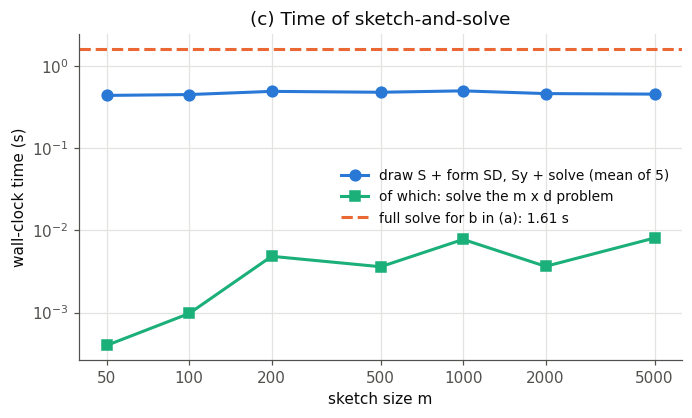

In [9]:
summary_c = g[["t_draw", "t_form", "t_solve", "t_total"]].mean()
summary_c["full_solve_time_a"] = time_a
summary_c["speedup"] = time_a / summary_c.t_total
summary_c.to_csv(RES / "q2c_times.csv")
with pd.option_context("display.float_format", "{:.4f}".format):
    print(summary_c.to_string())
print(f"\ntime to compute b in (a): {time_a:.3f} s")

fig, ax = plt.subplots(figsize=(6.4, 3.9))
ax.plot(ms, summary_c.t_total, "o-", color=C1, label="draw S + form SD, Sy + solve (mean of 5)")
ax.plot(ms, summary_c.t_solve, "s-", color=C3, label="of which: solve the m x d problem")
ax.axhline(time_a, color=C2, ls="--", label=f"full solve for b in (a): {time_a:.2f} s")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks(M_LIST); ax.set_xticklabels([str(m) for m in M_LIST]); ax.minorticks_off()
ax.set_xlabel("sketch size m"); ax.set_ylabel("wall-clock time (s)")
ax.set_title("(c) Time of sketch-and-solve")
ax.legend(loc="center right", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "q2c_times.png"); plt.show()

## Part (d): One fixed vector, many sketches: $\|Sv\|_2^2/\|v\|_2^2$

$v=Db-y$ is fixed before any $S$ is drawn. This is exactly the JL setting: one vector, a random map.
For each $m\in\{50,500,5000\}$ we draw 100 independent CountSketches and compute $\|Sv\|_2^2/\|v\|_2^2$.

Theory (derived in the report): $\mathbb{E}\,\|Sv\|_2^2=\|v\|_2^2$ and
$\operatorname{Var}\big(\|Sv\|_2^2/\|v\|_2^2\big)=\frac{2}{m}\Big(1-\frac{\|v\|_4^4}{\|v\|_2^4}\Big)\approx\frac{2}{m}$.

In [10]:
v = D @ b - y
v2 = float(v @ v)
flat = 1 - np.sum(v**4) / v2**2                    # 1 - ||v||_4^4 / ||v||_2^4, close to 1 for a spread-out v
M_D, N_SKETCH = [50, 500, 5000], 100
ratios_d = {}
for m in M_D:
    vals = []
    for _ in range(N_SKETCH):
        h, sigma = draw_countsketch(rng_d, m, n)
        Sv = apply_countsketch(h, sigma, m, v)
        vals.append(float(Sv @ Sv) / v2)
    ratios_d[m] = np.array(vals)

summary_d = pd.DataFrame({
    "mean": {m: r_.mean() for m, r_ in ratios_d.items()},
    "std": {m: r_.std(ddof=1) for m, r_ in ratios_d.items()},
    "min": {m: r_.min() for m, r_ in ratios_d.items()},
    "max": {m: r_.max() for m, r_ in ratios_d.items()},
    "theory_std": {m: np.sqrt(2 / m * flat) for m in M_D},
})
summary_d.index.name = "m"
summary_d.to_csv(RES / "q2d_summary.csv")
pd.DataFrame(ratios_d).to_csv(RES / "q2d_all_ratios.csv", index_label="sketch")
print(f"||v||^2 = {v2:.4f} (= Loss(D,y,b));  1 - ||v||_4^4/||v||_2^4 = {flat:.6f}")
with pd.option_context("display.float_format", "{:.4f}".format):
    print(summary_d.to_string())

||v||^2 = 2949.7888 (= Loss(D,y,b));  1 - ||v||_4^4/||v||_2^4 = 0.999842
       mean    std    min    max  theory_std
m                                           
50   1.0206 0.2117 0.6444 1.6112      0.2000
500  0.9966 0.0562 0.8695 1.1497      0.0632
5000 1.0014 0.0195 0.9415 1.0417      0.0200


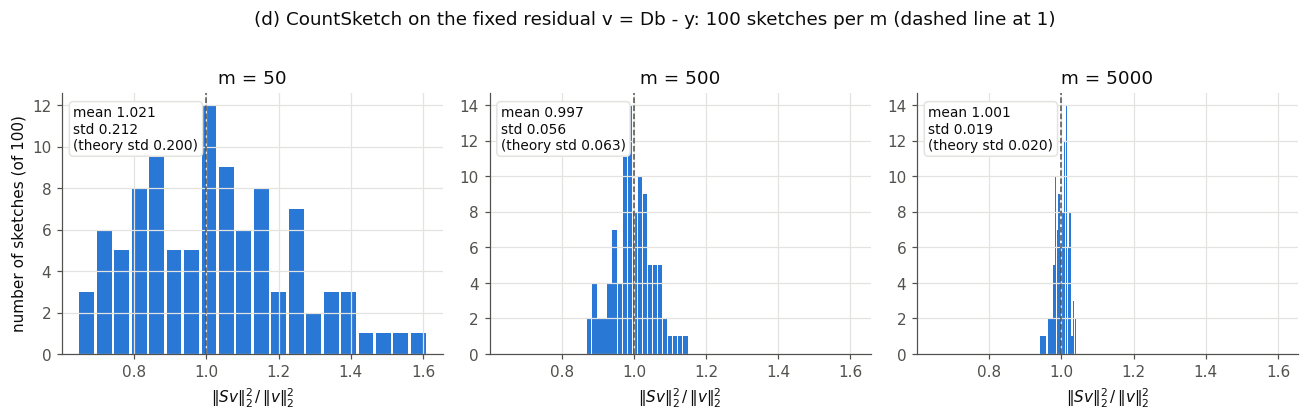

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), sharex=True)
for ax, m in zip(axes, M_D):
    vals = ratios_d[m]
    ax.hist(vals, bins=20, color=C1, rwidth=0.85)
    ax.axvline(1, color=INK2, ls="--", lw=1)
    s = summary_d.loc[m]
    ax.set_title(f"m = {m}")
    ax.text(0.03, 0.95, f"mean {s['mean']:.3f}\nstd {s['std']:.3f}\n(theory std {s['theory_std']:.3f})",
            transform=ax.transAxes, va="top", ha="left", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=GRID))
    ax.set_xlabel(r"$\|Sv\|_2^2 \,/\, \|v\|_2^2$")
axes[0].set_ylabel("number of sketches (of 100)")
fig.suptitle("(d) CountSketch on the fixed residual v = Db - y: 100 sketches per m (dashed line at 1)", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "q2d_histograms.png"); plt.show()

## Part (e): CountSketch versus a dense Gaussian sketch on 50,000 rows

1. Select 50,000 rows uniformly at random without replacement, **once**, with a fixed seed (`rng_e_subset`).
   $D'$ holds these rows and $y'$ the matching labels; the same subset is used for both sketches and all 5 repetitions.
2. Solve the full problem on the subset: $b'=\arg\min_a\|D'a-y'\|_2^2$.
3. For $m=500$, in each of 5 repetitions, draw a fresh (i) CountSketch and (ii) dense $S\in\mathbb{R}^{500\times 50000}$ with i.i.d. $N(0,1/m)$ entries.
   Time drawing $S$ and forming $SD'$ and $Sy'$; then solve for $\tilde a$ and compute $\text{Loss}(D',y',\tilde a)/\text{Loss}(D',y',b')$.

In [12]:
N_SUB, M_E = 50_000, 500
idx = rng_e_subset.choice(n, size=N_SUB, replace=False)
D1, y1 = D[idx], y[idx]
b1 = lstsq(D1, y1)
loss_b1 = loss(D1, y1, b1)
rank_D1 = int(np.linalg.matrix_rank(D1))
print(f"D' is {D1.shape[0]} x {D1.shape[1]}, rank(D') = {rank_D1};  Loss(D', y', b') = {loss_b1:.4f}")

rows = []
for rep in range(1, REPS + 1):
    # (i) CountSketch
    t0 = time.perf_counter()
    h, sigma = draw_countsketch(rng_e_count, M_E, N_SUB)
    SD1 = apply_countsketch(h, sigma, M_E, D1)
    Sy1 = apply_countsketch(h, sigma, M_E, y1)
    t1 = time.perf_counter()
    a_t = lstsq(SD1, Sy1)
    rows.append(dict(sketch="CountSketch", rep=rep, t_sketch=t1 - t0, ratio=loss(D1, y1, a_t) / loss_b1))
    # (ii) dense Gaussian, entries N(0, 1/m)
    t0 = time.perf_counter()
    G = rng_e_gauss.normal(0.0, 1.0 / np.sqrt(M_E), size=(M_E, N_SUB))
    GD1, Gy1 = G @ D1, G @ y1
    t1 = time.perf_counter()
    a_t = lstsq(GD1, Gy1)
    rows.append(dict(sketch="Gaussian", rep=rep, t_sketch=t1 - t0, ratio=loss(D1, y1, a_t) / loss_b1))
del G
runs_e = pd.DataFrame(rows)
runs_e.to_csv(RES / "q2e_all_runs.csv", index=False)
summary_e = runs_e.groupby("sketch").agg(time_mean=("t_sketch", "mean"), ratio_mean=("ratio", "mean"),
                                          ratio_min=("ratio", "min"), ratio_max=("ratio", "max"))
summary_e.to_csv(RES / "q2e_summary.csv")
print(runs_e.pivot(index="rep", columns="sketch", values=["t_sketch", "ratio"]).round(4).to_string())
print()
with pd.option_context("display.float_format", "{:.4f}".format):
    print(summary_e.to_string())
print(f"reference mean ratio for a Gaussian sketch: 1 + r'/(m - r' - 1) = {1 + rank_D1 / (M_E - rank_D1 - 1):.4f}")

D' is 50000 x 116, rank(D') = 108;  Loss(D', y', b') = 231.1891


          t_sketch                ratio         
sketch CountSketch Gaussian CountSketch Gaussian
rep                                             
1           0.0544   0.2449      1.2456   1.2916
2           0.0488   0.2546      1.3376   1.2585
3           0.0473   0.2193      1.2798   1.2728
4           0.0480   0.2071      1.2163   1.2102
5           0.0637   0.2572      1.3719   1.2510

             time_mean  ratio_mean  ratio_min  ratio_max
sketch                                                  
CountSketch     0.0524      1.2903     1.2163     1.3719
Gaussian        0.2366      1.2568     1.2102     1.2916
reference mean ratio for a Gaussian sketch: 1 + r'/(m - r' - 1) = 1.2762


### Extra check for the last question: both sketches on the full $D$ (one run each, $m=500$)

To answer "which sketch would you use on the full $D$" with a measurement and not only an estimate, we time one run of each sketch on all $n$ rows.
The dense $S$ is $500\times 494{,}021$, about 2 GB in float64.

In [13]:
full = {}
t0 = time.perf_counter()
h, sigma = draw_countsketch(rng_full, M_E, n)
SD, Sy = apply_countsketch(h, sigma, M_E, D), apply_countsketch(h, sigma, M_E, y)
t1 = time.perf_counter()
full["CountSketch"] = dict(t_sketch=t1 - t0, ratio=loss(D, y, lstsq(SD, Sy)) / loss_b, S_storage_MB=2 * n * 8 / 1e6)

t0 = time.perf_counter()
G = rng_full.normal(0.0, 1.0 / np.sqrt(M_E), size=(M_E, n))
GD, Gy = G @ D, G @ y
t1 = time.perf_counter()
full["Gaussian"] = dict(t_sketch=t1 - t0, ratio=loss(D, y, lstsq(GD, Gy)) / loss_b, S_storage_MB=G.nbytes / 1e6)
del G
full_e = pd.DataFrame(full).T
full_e.to_csv(RES / "q2e_full_D_check.csv")
with pd.option_context("display.float_format", "{:.4f}".format):
    print(full_e.to_string())

             t_sketch  ratio  S_storage_MB
CountSketch    0.4709 1.2665        7.9043
Gaussian       2.9960 1.3261     1976.0840


## Save the numbers used in the report

In [14]:
results = dict(
    seed=SEED, numpy=np.__version__, pandas=pd.__version__, platform=platform.platform(), processor=CPU,
    n=n, d=d, n_onehot=n_onehot, constant_cols=constant_cols, rank_D=rank_D,
    n_attack=int(y.sum()), frac_attack=float(y.mean()),
    loss_b=loss_b, times_a=times_a, time_a=time_a, norm_b=float(np.linalg.norm(b)),
    tss=float(np.sum((y - y.mean())**2)), smin_D=float(sv[rank_D - 1]),
    v_norm2=v2, v_flatness=float(flat),
    n_sub=N_SUB, rank_D1=rank_D1, loss_b1=loss_b1, m_e=M_E,
)
(RES / "q2_results.json").write_text(json.dumps(results, indent=2))
print(json.dumps(results, indent=2))

{
  "seed": 558,
  "numpy": "1.26.4",
  "pandas": "2.3.2",
  "platform": "macOS-15.7.3-arm64-arm-64bit",
  "processor": "Apple M4",
  "n": 494021,
  "d": 116,
  "n_onehot": 118,
  "constant_cols": [
    "num_outbound_cmds",
    "is_host_login"
  ],
  "rank_D": 113,
  "n_attack": 396743,
  "frac_attack": 0.8030893423558918,
  "loss_b": 2949.788844030342,
  "times_a": [
    1.7126834171358496,
    1.5282536251470447,
    1.5309736670460552,
    1.6692375000566244,
    1.587340333033353
  ],
  "time_a": 1.6056977084837853,
  "norm_b": 135.29157515119286,
  "tss": 78122.92504569645,
  "smin_D": 0.10612471685198778,
  "v_norm2": 2949.788844030342,
  "v_flatness": 0.9998423039882616,
  "n_sub": 50000,
  "rank_D1": 108,
  "loss_b1": 231.18911626285552,
  "m_e": 500
}
